# 🎯 RFM Analysis — Who Are Our Best Customers?

RFM stands for **Recency, Frequency, Monetary.**

- **Recency** — how recently did they buy? Recent buyers are far more likely to buy again
- **Frequency** — how often do they buy? Frequent buyers are loyal
- **Monetary** — how much do they spend? High spenders are high value

Every customer gets a score of 1–5 on each dimension. Combined, these scores place every customer into a clear actionable segment.

---

In [15]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_style("whitegrid")

def find_project_root(marker_folder='02_Data', start=None, max_up=6):
    path = os.path.abspath(start or os.getcwd())
    for _ in range(max_up):
        if marker_folder in os.listdir(path):
            return path
        path = os.path.dirname(path)
    raise FileNotFoundError(f"Could not find '{marker_folder}' folder above {os.getcwd()}")

project_root = find_project_root()
data_dir = os.path.join(project_root, '02_Data', '02_Cleaned_Data')

orders = pd.read_csv(os.path.join(data_dir, 'orders_clean.csv'), parse_dates=['order_purchase_timestamp'])
payments = pd.read_csv(os.path.join(data_dir, 'payments_clean.csv'))

print("✅ Data loaded from:", data_dir)
print("Orders shape:", orders.shape)
print("Payments shape:", payments.shape)
print("\nOrders columns:", list(orders.columns))
print("Payments columns:", list(payments.columns))

✅ Data loaded from: /Users/divyanshaggarwal/Desktop/Intelligent-Customer-Analytics-Suite/02_Data/02_Cleaned_Data
Orders shape: (99441, 8)
Payments shape: (103886, 5)

Orders columns: ['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']
Payments columns: ['order_id', 'payment_sequential', 'payment_type', 'payment_installments', 'payment_value']


In [16]:
if 'order_status' in orders.columns:
    delivered = orders[orders['order_status'] == 'delivered'].copy()
else:
    delivered = orders.copy()

payments_per_order = payments.groupby('order_id')['payment_value'].sum().reset_index()

order_payments = delivered.merge(payments_per_order, on='order_id', how='inner')

print("✅ Data ready!")
order_payments.head()

✅ Data ready!


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,payment_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,38.71
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,141.46
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,179.12
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,72.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,28.62


## Step 1: Calculate RFM Values

---

In [17]:
reference_date = order_payments['order_purchase_timestamp'].max() + pd.Timedelta(days=1)

rfm = order_payments.groupby('customer_id').agg(
    Recency   = ('order_purchase_timestamp',
                 lambda x: (reference_date - x.max()).days),
    Frequency = ('order_id', 'count'),
    Monetary  = ('payment_value', 'sum')
).reset_index()

print("✅ RFM calculated!")
rfm.describe().round(2)

✅ RFM calculated!


,Recency,Frequency,Monetary
count,96477.00,96477.0,96477.00
mean,240.12,1.0,159.86
std,152.83,0.0,218.81
min,1.00,1.0,9.59
25%,116.00,1.0,61.88
50%,221.00,1.0,105.28
75%,350.00,1.0,176.33
max,696.00,1.0,13664.08


## Step 2: Score Each Customer 1–5

Scores are assigned using quantiles — top 20% of customers by recency get a score of 5, bottom 20% get a score of 1. This makes all customers comparable regardless of raw numbers.

---

In [18]:
rfm['R_score'] = pd.qcut(rfm['Recency'], q=5, labels=[5,4,3,2,1])
rfm['F_score'] = pd.qcut(rfm['Frequency'].rank(method='first'),
                          q=5, labels=[1,2,3,4,5])
rfm['M_score'] = pd.qcut(rfm['Monetary'], q=5, labels=[1,2,3,4,5])

print("✅ Scores assigned!")
rfm[['Recency','Frequency','Monetary','R_score','F_score','M_score']].head()

✅ Scores assigned!


,Recency,Frequency,Monetary,R_score,F_score,M_score
0,288,1,114.74,2,1,3
1,410,1,67.41,1,1,2
2,548,1,195.42,1,1,4
3,379,1,179.35,2,1,4
4,150,1,107.01,4,1,3


## Step 3: Assign Segments

Each segment tells the business exactly what to do:
- **Champions** → reward them, they're your most valuable customers
- **Loyal Customers** → upsell, they're already engaged
- **New Customers** → nurture early, convert to loyal
- **Potential Loyalists** → one good experience from becoming loyal
- **At Risk** → re-engage urgently before they're gone
- **Lost** → low-cost win-back only, don't over-invest

---

In [19]:
def assign_segment(row):
    r = int(row['R_score'])
    f = int(row['F_score'])
    if r >= 4 and f >= 4:   return 'Champions'
    elif r >= 3 and f >= 3: return 'Loyal Customers'
    elif r >= 4 and f <= 2: return 'New Customers'
    elif r <= 2 and f >= 3: return 'At Risk'
    elif r <= 2 and f <= 2: return 'Lost'
    else:                   return 'Potential Loyalists'

rfm['Segment'] = rfm.apply(assign_segment, axis=1)
print(rfm['Segment'].value_counts())

Segment
At Risk                23245
Loyal Customers        19245
New Customers          15606
Champions              15396
Lost                   15304
Potential Loyalists     7681
Name: count, dtype: int64


## Step 4: Visualize Segments

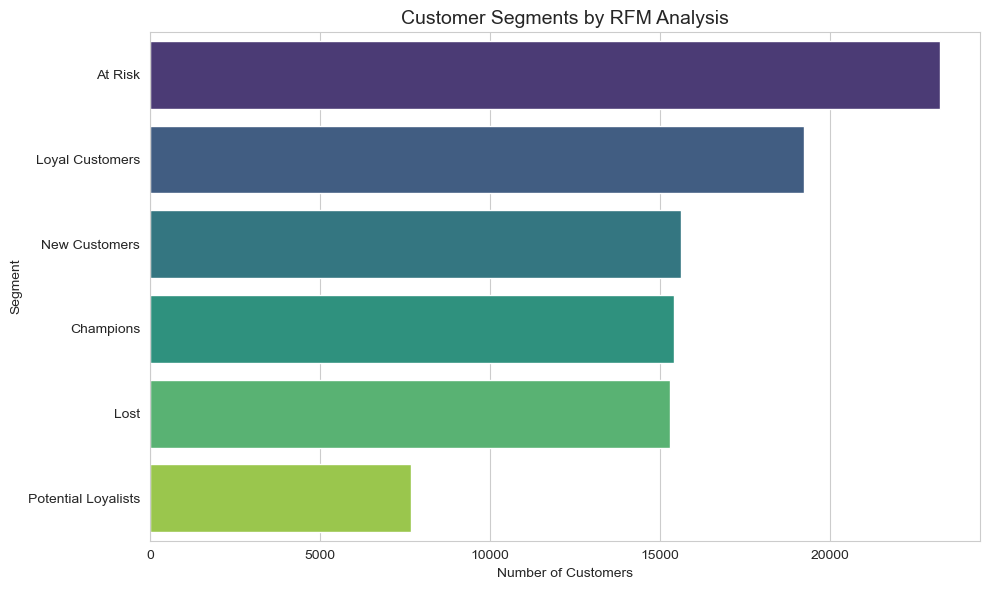

In [22]:
plt.figure(figsize=(10, 6))
segment_counts = rfm['Segment'].value_counts()
sns.barplot(x=segment_counts.values, y=segment_counts.index, palette='viridis')
plt.title('Customer Segments by RFM Analysis', fontsize=14)
plt.xlabel('Number of Customers')
plt.ylabel('Segment')
plt.tight_layout()
plt.show()

In [23]:
output_path = os.path.join(project_root, '02_Data', '03_Processed_Data', 'rfm_analysis.csv')
os.makedirs(os.path.dirname(output_path), exist_ok=True)
rfm.to_csv(output_path, index=False)
print("✅ Saved RFM results to:", output_path)

✅ Saved RFM results to: /Users/divyanshaggarwal/Desktop/Intelligent-Customer-Analytics-Suite/02_Data/03_Processed_Data/rfm_analysis.csv


## 💡 RFM Key Takeaways

- Majority fall into **Lost or At Risk** — confirms the retention crisis we saw in cohort analysis
- **Champions** are rare but drive disproportionate revenue — worth protecting at all costs
- **New Customers** segment shows acquisition is working — retention is what's broken
- Each segment needs a completely different strategy — not one-size-fits-all marketing

---